In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, FixedLocator
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool
import pandas as pd
import pickle
import scipy
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple#, HandlerTupleVertical

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

In [2]:
with open('pickled/mcmc_0.001_16_20000_fx0.1_2024-11-12_21-10-31.pkl', 'rb') as h:
    mcmc_output = pickle.load(h)
#with open('pickled/mcmc_0.001_64_40000_2024-10-07_01-57-30.pkl', 'rb') as h:
#    mcmc_output = pickle.load(h)

(21328, 2)


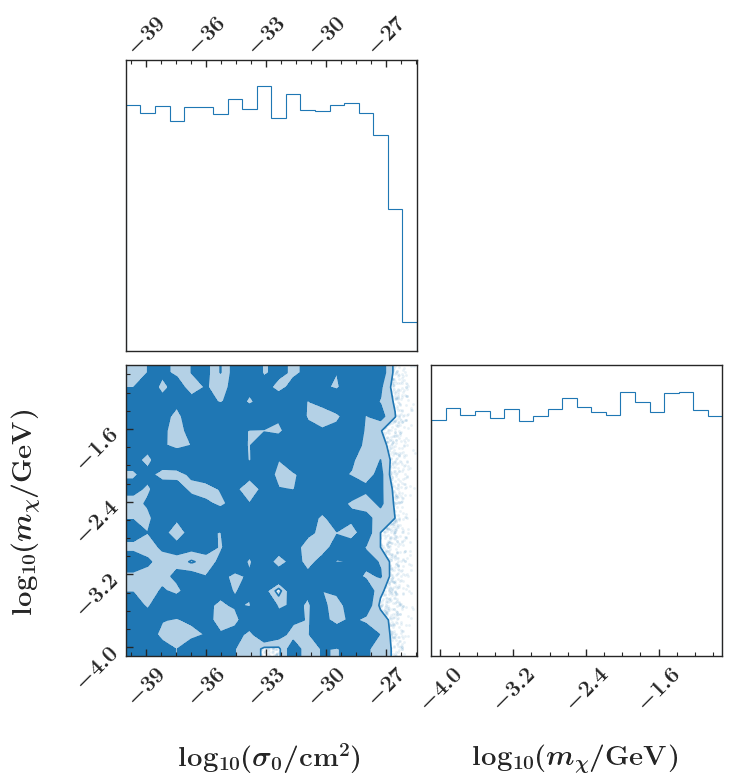

2024-11-12T21:22:53.995185: made plots/corner_plot.png


In [5]:
# create corner plot of results
paper_plot()

print(mcmc_output.shape)
figure = plt.figure(figsize=(8, 8))



labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output, 
    labels=labels, 
    dpi=450, 
    #smooth=4.5, 
    levels=[0.68, 0.95], 
    top_ticks=True, 
    color='#1f77b4',
    fill_contours=True,
    plot_density=True,
    #contourf_kwargs={"alpha":0.5}, 
    scatter_kws={"alpha": 0}, 
    fig=figure,
    zorder=1
);


# Access the axes of the corner plot
axes = figure.get_axes()

# Enable minor ticks and customize tick parameters for each subplot
for ax in axes:
    ax.minorticks_on()
    ax.tick_params(which='both', direction='in')
    #ax.set_xticks(np.arange(-40, -25, 3))  # Set major ticks for x-axis
    #ax.set_yticks(np.arange(-4, -0.5, 0.5))  # Set major ticks for y-axis
    ax.xaxis.set_zorder(10)  # Higher zorder for x-ticks
    ax.yaxis.set_zorder(10)  # Higher zorder for y-ticks

plt.show()
#savefig(fig, 'plots/corner_plot.png', dpi=450)

In [7]:
np.median(mcmc_output[:, 0]), np.median(mcmc_output[:, 1])

(-33.21219680893758, -2.476196560900818)